In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
testset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)


100%|██████████| 170M/170M [00:04<00:00, 41.4MB/s]


In [2]:
class FairCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(FairCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.1),

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.2),

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Block 4
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        # Global Average Pooling
        self.gap = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FairCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=15, gamma=0.5
)


In [ ]:
epochs = 50

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"[CNN] Epoch {epoch+1}/{epochs}  Loss: {running_loss/len(trainloader):.4f}  Accuracy: {accuracy:.2f}%")

print("CNN Training finished!")


[CNN] Epoch 1/50  Loss: 1.3607  Accuracy: 59.15%
[CNN] Epoch 2/50  Loss: 1.2069  Accuracy: 64.54%
[CNN] Epoch 3/50  Loss: 1.1236  Accuracy: 67.38%
[CNN] Epoch 4/50  Loss: 1.0603  Accuracy: 68.34%
[CNN] Epoch 5/50  Loss: 1.0175  Accuracy: 71.53%
[CNN] Epoch 6/50  Loss: 0.9802  Accuracy: 71.45%
[CNN] Epoch 7/50  Loss: 0.9398  Accuracy: 72.98%
[CNN] Epoch 8/50  Loss: 0.9134  Accuracy: 74.67%
[CNN] Epoch 9/50  Loss: 0.8838  Accuracy: 74.50%
[CNN] Epoch 10/50  Loss: 0.8633  Accuracy: 74.79%
[CNN] Epoch 11/50  Loss: 0.8496  Accuracy: 76.24%
[CNN] Epoch 12/50  Loss: 0.8312  Accuracy: 78.14%
[CNN] Epoch 13/50  Loss: 0.8203  Accuracy: 77.43%
[CNN] Epoch 14/50  Loss: 0.8009  Accuracy: 78.22%
[CNN] Epoch 15/50  Loss: 0.7960  Accuracy: 78.94%
[CNN] Epoch 16/50  Loss: 0.7554  Accuracy: 79.99%
[CNN] Epoch 17/50  Loss: 0.7418  Accuracy: 80.71%
[CNN] Epoch 18/50  Loss: 0.7316  Accuracy: 80.17%
[CNN] Epoch 19/50  Loss: 0.7309  Accuracy: 80.93%
[CNN] Epoch 20/50  Loss: 0.7241  Accuracy: 80.89%
[CNN] Epo

Aperçu des images d'entraînement (Data Augmentation appliquée) :


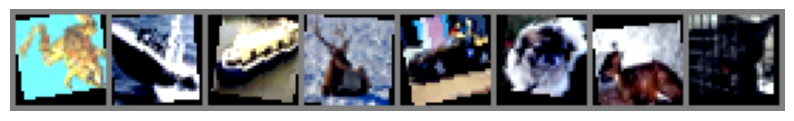

Labels : grenouille bateau bateau cerf  auto  chien cerf  chat 


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torchvision

# Fonction pour dénormaliser 
def imshow(img):
    img = img / 2 + 0.5     # Dénormalisation
    npimg = img.numpy()
    plt.figure(figsize=(10, 10))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

# Noms des classes CIFAR-10
classes = ('avion', 'auto', 'oiseau', 'chat', 'cerf', 'chien', 'grenouille', 'cheval', 'bateau', 'camion')

print("Aperçu des images d'entraînement (Data Augmentation appliquée) :")
imshow(torchvision.utils.make_grid(images[:8]))
print('Labels :', ' '.join(f'{classes[labels[j]]:5s}' for j in range(8)))

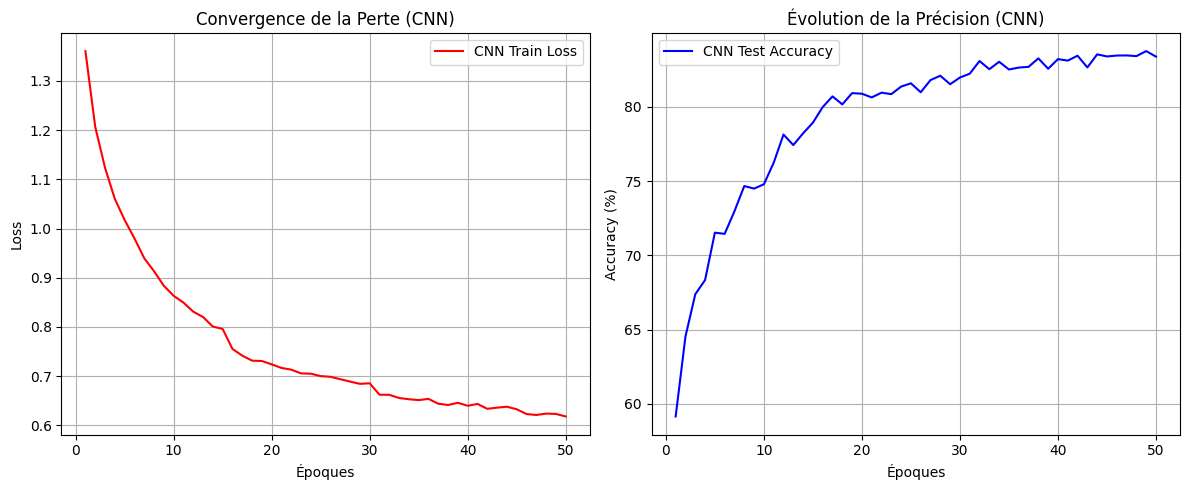

In [ ]:
import matplotlib.pyplot as plt



history_loss_cnn = [
    1.3607, 1.2069, 1.1236, 1.0603, 1.0175, 0.9802, 0.9398, 0.9134, 0.8838, 0.8633,
    0.8496, 0.8312, 0.8203, 0.8009, 0.7960, 0.7554, 0.7418, 0.7316, 0.7309, 0.7241,
    0.7168, 0.7133, 0.7057, 0.7051, 0.7002, 0.6988, 0.6939, 0.6891, 0.6845, 0.6856,
    0.6624, 0.6621, 0.6557, 0.6532, 0.6514, 0.6539, 0.6440, 0.6415, 0.6460, 0.6399,
    0.6437, 0.6337, 0.6361, 0.6380, 0.6328, 0.6231, 0.6212, 0.6240, 0.6233, 0.6182
]

history_acc_cnn = [
    59.15, 64.54, 67.38, 68.34, 71.53, 71.45, 72.98, 74.67, 74.50, 74.79,
    76.24, 78.14, 77.43, 78.22, 78.94, 79.99, 80.71, 80.17, 80.93, 80.89,
    80.64, 80.96, 80.86, 81.37, 81.59, 80.99, 81.81, 82.10, 81.53, 81.98,
    82.24, 83.09, 82.54, 83.04, 82.52, 82.65, 82.70, 83.27, 82.57, 83.22,
    83.12, 83.45, 82.66, 83.54, 83.40, 83.46, 83.47, 83.42, 83.76, 83.39
]

epochs_range = range(1, len(history_loss_cnn) + 1)

plt.figure(figsize=(12, 5))

# Graphique Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_loss_cnn, color='red', label='CNN Train Loss')
plt.title('Convergence de la Perte (CNN)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Graphique Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_acc_cnn, color='blue', label='CNN Test Accuracy')
plt.title('Évolution de la Précision (CNN)')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()